<a href="https://colab.research.google.com/github/vtu27065/Deep-Learning/blob/main/Use%20Case%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

In [2]:
dates = pd.date_range(
    start="2023-01-01",
    periods=36,
    freq="MS"
)

sales = [
    120, 125, 130, 128, 140, 145,
    150, 148, 155, 160, 170, 180,
    135, 140, 145, 142, 155, 160,
    165, 163, 170, 175, 185, 195,
    150, 155, 160, 158, 170, 175,
    180, 178, 185, 190, 200, 210
]

df = pd.DataFrame({
    "Date": dates,
    "Sales": sales
})

df.set_index("Date", inplace=True)

print(df.head())

            Sales
Date             
2023-01-01    120
2023-02-01    125
2023-03-01    130
2023-04-01    128
2023-05-01    140


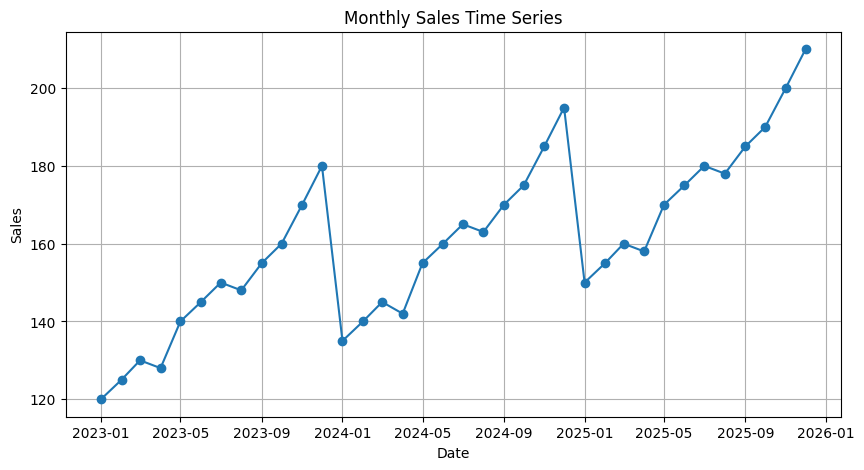

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(df.index, df["Sales"], marker="o")
plt.title("Monthly Sales Time Series")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

In [4]:
train = df.iloc[:30]
test = df.iloc[30:]

print("Training data:", len(train))
print("Testing data:", len(test))

Training data: 30
Testing data: 6


In [5]:
model = ARIMA(train["Sales"], order=(1, 1, 1))
model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   30
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -115.689
Date:                Thu, 22 Oct 2026   AIC                            237.378
Time:                        12:02:15   BIC                            241.480
Sample:                    01-01-2023   HQIC                           238.663
                         - 06-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5514      1.646      0.335      0.738      -2.676       3.778
ma.L1         -0.8005      1.064     -0.752      0.452      -2.887       1.286
sigma2       169.5248     60.052      2.823      0.0

In [6]:
predictions = model_fit.forecast(steps=len(test))

results = pd.DataFrame({
    "Actual Sales": test["Sales"],
    "Predicted Sales": predictions
})

print(results.round(2))

            Actual Sales  Predicted Sales
2025-07-01           180           172.34
2025-08-01           178           170.88
2025-09-01           185           170.07
2025-10-01           190           169.63
2025-11-01           200           169.38
2025-12-01           210           169.25


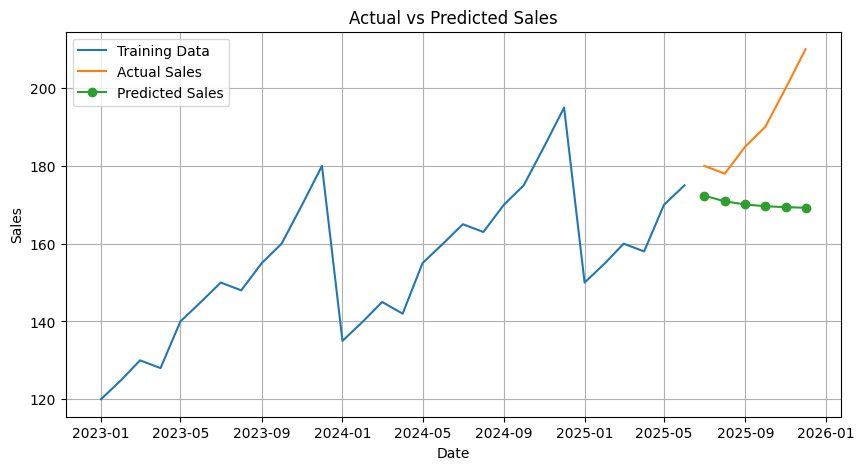

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(train.index, train["Sales"], label="Training Data")
plt.plot(test.index, test["Sales"], label="Actual Sales")
plt.plot(test.index, predictions, label="Predicted Sales",
         marker="o")

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
mae = mean_absolute_error(
    test["Sales"],
    predictions
)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 20.24


In [9]:
final_model = ARIMA(df["Sales"], order=(1, 1, 1))
final_fit = final_model.fit()

future_forecast = final_fit.forecast(steps=6)

future_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecasted Sales": future_forecast.values
})

print(forecast_df.round(2))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


        Date  Forecasted Sales
0 2026-01-01            206.42
1 2026-02-01            204.37
2 2026-03-01            203.19
3 2026-04-01            202.52
4 2026-05-01            202.13
5 2026-06-01            201.91


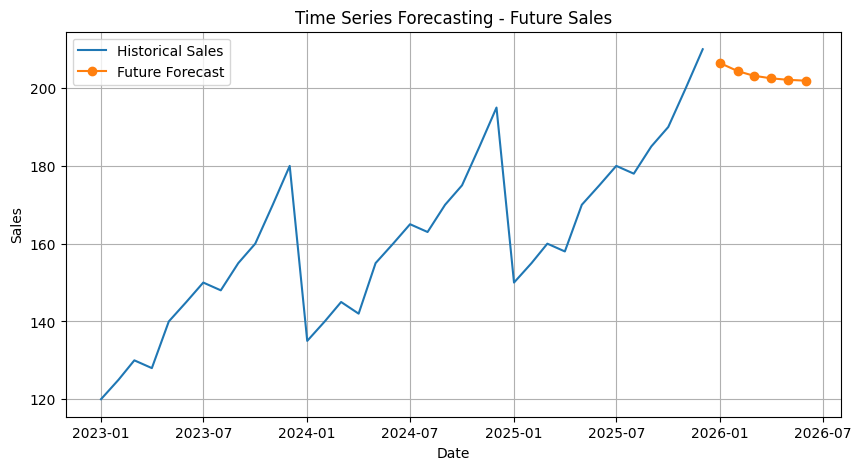

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(df.index, df["Sales"], label="Historical Sales")
plt.plot(future_dates, future_forecast,
         marker="o", label="Future Forecast")

plt.title("Time Series Forecasting - Future Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()